<a href="https://colab.research.google.com/github/mohiuddin2806-lang/machine-learning-/blob/main/CN7031_week_6_u297526.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# @title ▶ 1.1 Install Java 17 and Apache Spark (PySpark 4.0.4)
# Import the tools used to run installation commands and check the result.
import os
import subprocess
import sys
from pathlib import Path

# Spark runs on the Java Virtual Machine; Spark 4 needs Java 17 or newer.
SPARK_VERSION = '4.0.4'
JAVA = Path('/usr/lib/jvm/java-17-openjdk-amd64')

# Run a system command and stop with a useful error if it fails.
def checked(args, timeout=900):
    p = subprocess.run(args, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=timeout)
    if p.returncode:
        raise RuntimeError(p.stdout[-5000:])
    return p.stdout

# Install Java 17 only when it is not already on this VM.
if not (JAVA / 'bin/java').exists():
    print('Installing Java 17 …')
    checked(['apt-get', 'update', '-qq'])
    checked(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'])

# Point Spark at Java 17.
os.environ['JAVA_HOME'] = str(JAVA)
os.environ['PATH'] = f'{JAVA}/bin:' + os.environ['PATH']

# Install the PySpark package (Spark itself is bundled inside it), only if this version is missing.
from importlib.metadata import version, PackageNotFoundError
try:
    installed = version('pyspark')
except PackageNotFoundError:
    installed = None
if installed != SPARK_VERSION:
    print(f'Installing PySpark {SPARK_VERSION} (about 450 MB) …')
    checked([sys.executable, '-m', 'pip', 'install', '-q', f'pyspark=={SPARK_VERSION}'])
    if 'pyspark' in sys.modules:
        print('An older PySpark was already loaded: choose Runtime → Restart session, then run this cell again.')

# Spark's own log messages (INFO and WARN) would fill the cell outputs: show only errors.
SPARK_CONF = Path('/content/spark-conf')
SPARK_CONF.mkdir(parents=True, exist_ok=True)
(SPARK_CONF / 'log4j2.properties').write_text(
    'rootLogger.level = error\n'
    'rootLogger.appenderRef.stdout.ref = console\n'
    'appender.console.type = Console\n'
    'appender.console.name = console\n'
    'appender.console.target = SYSTEM_ERR\n'
    'appender.console.layout.type = PatternLayout\n'
    'appender.console.layout.pattern = %p %c{1}: %m%n\n'
    'logger.repl.name = org.apache.spark.repl.Main\n'
    'logger.repl.level = error\n')
os.environ['SPARK_CONF_DIR'] = str(SPARK_CONF)

# Java's start-up notices go to a log file instead of the notebook (Spark errors still appear in Python).
import pyspark.java_gateway as java_gateway
if not getattr(java_gateway.Popen, 'quiet', False):
    start_java = java_gateway.Popen
    def quiet_popen(command, **kwargs):
        kwargs.setdefault('stderr', open(SPARK_CONF / 'java.log', 'ab'))
        return start_java(command, **kwargs)
    quiet_popen.quiet = True
    java_gateway.Popen = quiet_popen

# When a query has a mistake, show only Python's short error message, not an extra JSON log of it.
from pyspark.logger import PySparkLogger
for name in ('SQLQueryContextLogger', 'DataFrameQueryContextLogger'):
    PySparkLogger.getLogger(name).disabled = True

# Show what was installed.
java_version = checked([str(JAVA / 'bin/java'), '-version']).splitlines()[0]
print(java_version)
print(f'PySpark {SPARK_VERSION} is installed ✓  Java 17 is ready ✓')

Installing Java 17 …
Installing PySpark 4.0.4 (about 450 MB) …
openjdk version "17.0.21.0.3" 2026-10-24
PySpark 4.0.4 is installed ✓  Java 17 is ready ✓


In [2]:
# Download the KDD Cup 99 data (the 10% sample), trying the official UCI site first.
import urllib.request
import gzip
import socket
socket.setdefaulttimeout(60)
urls = ["http://kdd.ics.uci.edu/databases/kddcup99/kddcup.data_10_percent.gz",
        "https://www.dropbox.com/s/qz62t2oyllkl32s/kddcup.data_10_percent.gz?dl=1",
        "https://raw.githubusercontent.com/ansvad/pyspark/master/kddcup.data_10_percent.gz"]
for url in urls:
    try:
        urllib.request.urlretrieve(url, "kddcup.data_10_percent.gz")
        with gzip.open("kddcup.data_10_percent.gz") as f:
            f.readline()
        print("Downloaded from", url.split("/")[2])
        break
    except Exception as error:
        print("Not available:", url.split("/")[2], "-", type(error).__name__)
!ls -lh kddcup.data_10_percent.gz

Not available: kdd.ics.uci.edu - HTTPError
Downloaded from www.dropbox.com
-rw-r--r-- 1 root root 2.1M Nov 12 20:05 kddcup.data_10_percent.gz


In [4]:
# Create the SparkSession, then show its version and where it runs.
from pyspark.sql import SparkSession
spark = SparkSession \
.builder \
.appName("Python spark SQL basic example") \
.master("local[*]") \
.getOrCreate()
print("Spark", spark.version, ".master:", spark.sparkContext.master)

Spark 4.0.4 .master: local[*]


In [5]:
# Show the first three connections in the compressed file.
!zcat kddcup.data_10_percent.gz 2>/dev/null | head -n 3

0,tcp,http,SF,181,5450,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,9,9,1.00,0.00,0.11,0.00,0.00,0.00,0.00,0.00,normal.
0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,19,19,1.00,0.00,0.05,0.00,0.00,0.00,0.00,0.00,normal.
0,tcp,http,SF,235,1337,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,29,29,1.00,0.00,0.03,0.00,0.00,0.00,0.00,0.00,normal.


In [6]:
# Create a DataFrame based on the content of the KDD Cup file, and show its first 20 rows.
df=spark.read.csv("kddcup.data_10_percent.gz")
df.show()

+---+---+----+---+---+----+---+---+---+---+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+-------+
|_c0|_c1| _c2|_c3|_c4| _c5|_c6|_c7|_c8|_c9|_c10|_c11|_c12|_c13|_c14|_c15|_c16|_c17|_c18|_c19|_c20|_c21|_c22|_c23|_c24|_c25|_c26|_c27|_c28|_c29|_c30|_c31|_c32|_c33|_c34|_c35|_c36|_c37|_c38|_c39|_c40|   _c41|
+---+---+----+---+---+----+---+---+---+---+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+----+-------+
|  0|tcp|http| SF|181|5450|  0|  0|  0|  0|   0|   1|   0|   0|   0|   0|   0|   0|   0|   0|   0|   0|   8|   8|0.00|0.00|0.00|0.00|1.00|0.00|0.00|   9|   9|1.00|0.00|0.11|0.00|0.00|0.00|0.00|0.00|normal.|
|  0|tcp|http| SF|239| 486|  0|  0|  0|  0|   0|   1|   0|   0|   0|   0|   0|   0|   0|   0|   0|   0|   8|   8|0.00|0.00|0.00|0.00|1.00|0.00|0.00|  19|  19|1.00|0.00|0.05

In [7]:
# List the column names.
df.columns

['_c0',
 '_c1',
 '_c2',
 '_c3',
 '_c4',
 '_c5',
 '_c6',
 '_c7',
 '_c8',
 '_c9',
 '_c10',
 '_c11',
 '_c12',
 '_c13',
 '_c14',
 '_c15',
 '_c16',
 '_c17',
 '_c18',
 '_c19',
 '_c20',
 '_c21',
 '_c22',
 '_c23',
 '_c24',
 '_c25',
 '_c26',
 '_c27',
 '_c28',
 '_c29',
 '_c30',
 '_c31',
 '_c32',
 '_c33',
 '_c34',
 '_c35',
 '_c36',
 '_c37',
 '_c38',
 '_c39',
 '_c40',
 '_c41']

In [9]:
# Rename the 42 columns with the feature names, then list them.
df2 = df.withColumnRenamed("_c0", "duration") \
    .withColumnRenamed("_c1", "protocol_type") \
    .withColumnRenamed("_c2", "service") \
    .withColumnRenamed("_c3", "flag") \
    .withColumnRenamed("_c4", "src_bytes") \
    .withColumnRenamed("_c5", "dst_bytes") \
    .withColumnRenamed("_c6", "land") \
    .withColumnRenamed("_c7", "wrong_fragment") \
    .withColumnRenamed("_c8", "urgent") \
    .withColumnRenamed("_c9", "hot") \
    .withColumnRenamed("_c10", "num_failed_logins") \
    .withColumnRenamed("_c11", "logged_in") \
    .withColumnRenamed("_c12", "num_compromised") \
    .withColumnRenamed("_c13", "root_shell") \
    .withColumnRenamed("_c14", "su_attempted") \
    .withColumnRenamed("_c15", "num_root") \
    .withColumnRenamed("_c16", "num_file_creations") \
    .withColumnRenamed("_c17", "num_shells") \
    .withColumnRenamed("_c18", "num_access_files") \
    .withColumnRenamed("_c19", "num_outbound_cmds") \
    .withColumnRenamed("_c20", "is_host_login") \
    .withColumnRenamed("_c21", "is_guest_login") \
    .withColumnRenamed("_c22", "count") \
    .withColumnRenamed("_c23", "srv_count") \
    .withColumnRenamed("_c24", "serror_rate") \
    .withColumnRenamed("_c25", "srv_serror_rate") \
    .withColumnRenamed("_c26", "rerror_rate") \
    .withColumnRenamed("_c27", "srv_rerror_rate") \
    .withColumnRenamed("_c28", "same_srv_rate") \
    .withColumnRenamed("_c29", "diff_srv_rate") \
    .withColumnRenamed("_c30", "srv_diff_host_rate") \
    .withColumnRenamed("_c31", "dst_host_count") \
    .withColumnRenamed("_c32", "dst_host_srv_count") \
    .withColumnRenamed("_c33", "dst_host_same_srv_rate") \
    .withColumnRenamed("_c34", "dst_host_diff_srv_rate") \
    .withColumnRenamed("_c35", "dst_host_same_src_port_rate") \
    .withColumnRenamed("_c36", "dst_host_srv_diff_host_rate") \
    .withColumnRenamed("_c37", "dst_host_serror_rate") \
    .withColumnRenamed("_c38", "dst_host_srv_serror_rate") \
    .withColumnRenamed("_c39", "dst_host_rerror_rate") \
    .withColumnRenamed("_c40", "dst_host_srv_rerror_rate") \
    .withColumnRenamed("_c41", "connection_status")

df2.columns

['duration',
 'protocol_type',
 'service',
 'flag',
 'src_bytes',
 'dst_bytes',
 'land',
 'wrong_fragment',
 'urgent',
 'hot',
 'num_failed_logins',
 'logged_in',
 'num_compromised',
 'root_shell',
 'su_attempted',
 'num_root',
 'num_file_creations',
 'num_shells',
 'num_access_files',
 'num_outbound_cmds',
 'is_host_login',
 'is_guest_login',
 'count',
 'srv_count',
 'serror_rate',
 'srv_serror_rate',
 'rerror_rate',
 'srv_rerror_rate',
 'same_srv_rate',
 'diff_srv_rate',
 'srv_diff_host_rate',
 'dst_host_count',
 'dst_host_srv_count',
 'dst_host_same_srv_rate',
 'dst_host_diff_srv_rate',
 'dst_host_same_src_port_rate',
 'dst_host_srv_diff_host_rate',
 'dst_host_serror_rate',
 'dst_host_srv_serror_rate',
 'dst_host_rerror_rate',
 'dst_host_srv_rerror_rate',
 'connection_status']

In [11]:
# Register the DataFrame as a SQL temporary view called KddView, then retrieve its content.
df2.createOrReplaceTempView("KddView")
sqlDF = spark.sql("SELECT * FROM KddView")
sqlDF.show()

+--------+-------------+-------+----+---------+---------+----+--------------+------+---+-----------------+---------+---------------+----------+------------+--------+------------------+----------+----------------+-----------------+-------------+--------------+-----+---------+-----------+---------------+-----------+---------------+-------------+-------------+------------------+--------------+------------------+----------------------+----------------------+---------------------------+---------------------------+--------------------+------------------------+--------------------+------------------------+-----------------+
|duration|protocol_type|service|flag|src_bytes|dst_bytes|land|wrong_fragment|urgent|hot|num_failed_logins|logged_in|num_compromised|root_shell|su_attempted|num_root|num_file_creations|num_shells|num_access_files|num_outbound_cmds|is_host_login|is_guest_login|count|srv_count|serror_rate|srv_serror_rate|rerror_rate|srv_rerror_rate|same_srv_rate|diff_srv_rate|srv_diff_host_ra

In [12]:
# Import NumPy, Matplotlib and pandas for the charts.
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
print("pandas",pd.__version__,".Numpy", np.__version__)

pandas 2.2.3 .Numpy 2.4.6


In [14]:
# Query 1: List the number of connections for the different connection statuses.
sqlDF = spark.sql("SELECT connection_status, COUNT(*) FROM KddView GROUP BY connection_status")
sqlDF.show()

+-----------------+--------+
|connection_status|count(1)|
+-----------------+--------+
|     warezmaster.|      20|
|           smurf.|  280790|
|             pod.|     264|
|            imap.|      12|
|            nmap.|     231|
|    guess_passwd.|      53|
|         ipsweep.|    1247|
|       portsweep.|    1040|
|           satan.|    1589|
|            land.|      21|
|      loadmodule.|       9|
|       ftp_write.|       8|
| buffer_overflow.|      30|
|         rootkit.|      10|
|     warezclient.|    1020|
|        teardrop.|     979|
|            perl.|       3|
|             phf.|       4|
|        multihop.|       7|
|         neptune.|  107201|
+-----------------+--------+
only showing top 20 rows


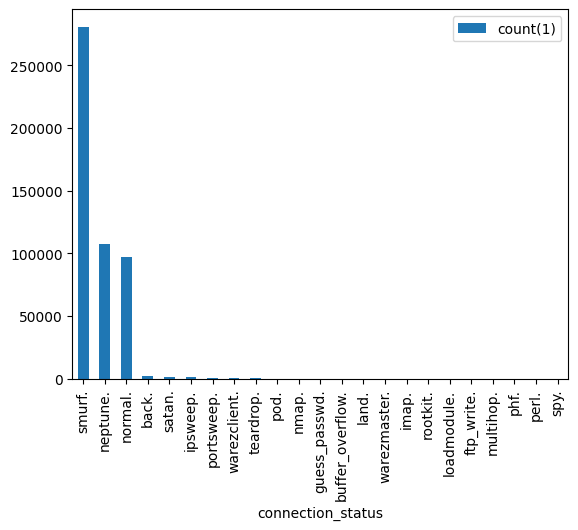

In [16]:
# Plot the number of connections for each status as a bar chart, largest first.
Pandas_df=sqlDF.toPandas()
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='connection_status', y='count(1)', kind='bar')
plt.show()

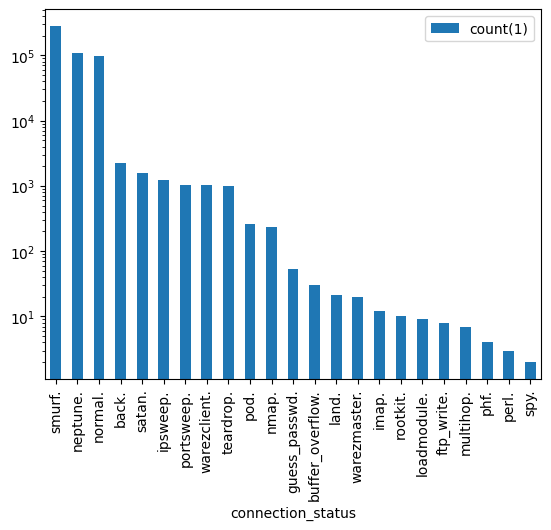

In [17]:
# Plot the same chart with a logarithmic Y axis.
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='connection_status', y='count(1)', kind='bar', logy=True)
plt.show()

In [18]:
# Query 2: List the number of connections for each protocol type.
sqlDF = spark.sql("SELECT protocol_type, COUNT(*) FROM KddView GROUP BY protocol_type")
sqlDF.show()

+-------------+--------+
|protocol_type|count(1)|
+-------------+--------+
|          tcp|  190065|
|          udp|   20354|
|         icmp|  283602|
+-------------+--------+



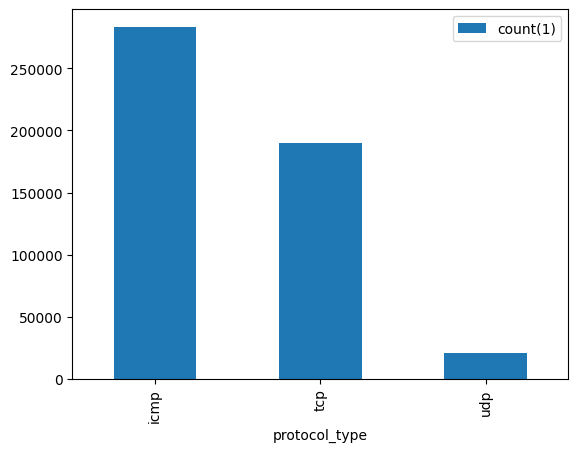

In [19]:
# Plot the number of connections for each protocol type as a bar chart.
Pandas_df=sqlDF.toPandas()
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='protocol_type', y='count(1)', kind='bar')
plt.show()

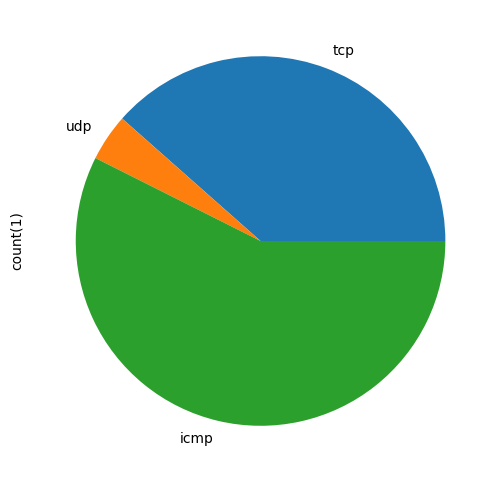

In [20]:
# Plot the protocol types as a pie chart.

Pandas_df.set_index('protocol_type').plot(y='count(1)', kind='pie', legend=False, figsize=(6, 6))
plt.show()

In [22]:
# Query 3: List the services used for udp connections that are not host logins.
sqlDF = spark.sql("SELECT DISTINCT service from KddView where is_host_login=0 and protocol_type = 'udp'")
sqlDF.show()

+--------+
| service|
+--------+
|   ntp_u|
|  tftp_u|
|domain_u|
|   other|
| private|
+--------+



In [23]:
# Query 4: List the number of connections for each service used for udp connections that are not host logins.
sqlDF = spark.sql("SELECT service, COUNT(*) FROM KddView where is_host_login=0 and protocol_type = 'udp' GROUP BY service")
sqlDF.show()

+--------+--------+
| service|count(1)|
+--------+--------+
|   ntp_u|     380|
|  tftp_u|       1|
|domain_u|    5863|
|   other|    5598|
| private|    8512|
+--------+--------+



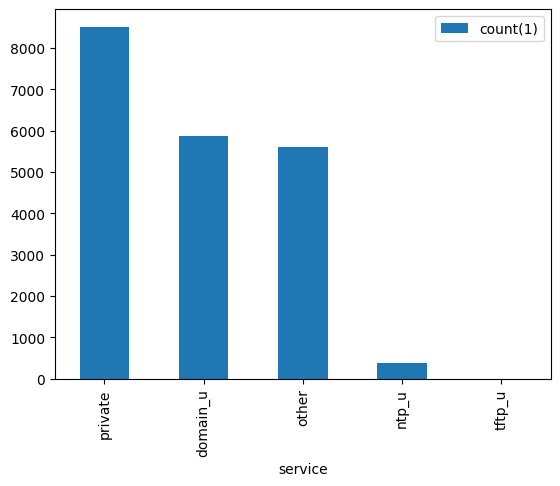

In [24]:
# Plot the udp services as a bar chart.
Pandas_df=sqlDF.toPandas()
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='service', y='count(1)', kind='bar')
plt.show()

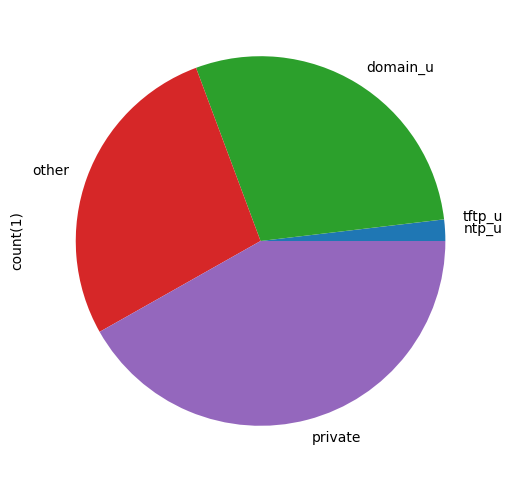

In [25]:
# Plot the udp services as a pie chart.
Pandas_df.set_index('service').plot(y='count(1)', kind='pie', legend=False, figsize=(6, 6))
plt.show()

In [26]:
# Query 5: List the different types of bad connections.
sqlDF = spark.sql("SELECT DISTINCT connection_status from KddView where connection_status<>'normal.'")
sqlDF.show()

+-----------------+
|connection_status|
+-----------------+
|     warezmaster.|
|           smurf.|
|             pod.|
|            imap.|
|            nmap.|
|    guess_passwd.|
|         ipsweep.|
|       portsweep.|
|           satan.|
|            land.|
|      loadmodule.|
|       ftp_write.|
| buffer_overflow.|
|         rootkit.|
|     warezclient.|
|        teardrop.|
|            perl.|
|             phf.|
|        multihop.|
|         neptune.|
+-----------------+
only showing top 20 rows


In [27]:
# Query 6: List the number of connections for each type of bad connection.
sqlDF = spark.sql("SELECT connection_status, COUNT(*) FROM KddView where connection_status<>'normal.' GROUP BY connection_status")
sqlDF.show()

+-----------------+--------+
|connection_status|count(1)|
+-----------------+--------+
|     warezmaster.|      20|
|           smurf.|  280790|
|             pod.|     264|
|            imap.|      12|
|            nmap.|     231|
|    guess_passwd.|      53|
|         ipsweep.|    1247|
|       portsweep.|    1040|
|           satan.|    1589|
|            land.|      21|
|      loadmodule.|       9|
|       ftp_write.|       8|
| buffer_overflow.|      30|
|         rootkit.|      10|
|     warezclient.|    1020|
|        teardrop.|     979|
|            perl.|       3|
|             phf.|       4|
|        multihop.|       7|
|         neptune.|  107201|
+-----------------+--------+
only showing top 20 rows


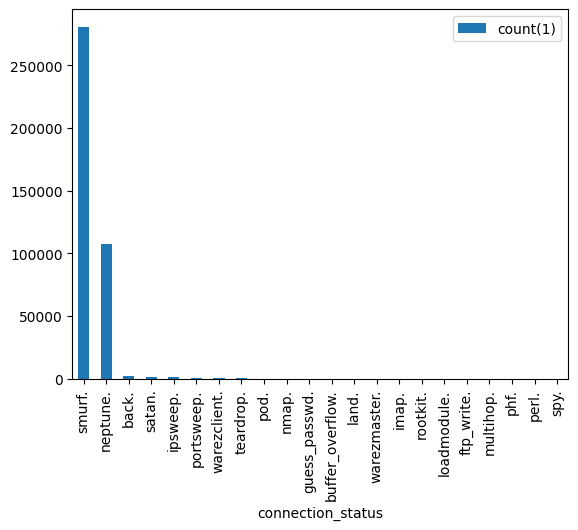

In [28]:
# Plot the bad connections as a bar chart.
Pandas_df=sqlDF.toPandas()
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='connection_status', y='count(1)', kind='bar')
plt.show()


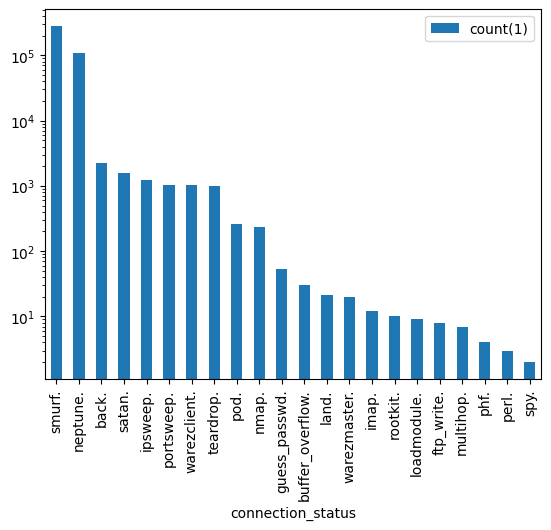

In [29]:
# Plot the bad connections with a logarithmic Y axis.
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='connection_status', y='count(1)', kind='bar', logy=True)
plt.show()

In [30]:
# Query 7: List the services of tcp connections that received more than 1000 bytes from the destination.
sqlDF=spark.sql("SELECT DISTINCT service from KddView where dst_bytes>1000 and protocol_type = 'tcp'")
sqlDF.show()

+--------+
| service|
+--------+
|  telnet|
|     ftp|
|     X11|
|   pop_3|
|   login|
|    smtp|
|    http|
|     IRC|
|ftp_data|
|   imap4|
|     ssh|
+--------+



In [31]:
# Query 8: List the number of connections for each service, for tcp connections that received more than 1000 bytes.
sqlDF=spark.sql("SELECT service, COUNT(*) FROM KddView where dst_bytes>1000 and protocol_type = 'tcp' GROUP BY service")
sqlDF.show()

+--------+--------+
| service|count(1)|
+--------+--------+
|  telnet|     239|
|     ftp|     551|
|     X11|       6|
|   pop_3|      42|
|   login|       2|
|    smtp|     168|
|    http|   39047|
|     IRC|      32|
|ftp_data|      36|
|   imap4|       2|
|     ssh|       1|
+--------+--------+



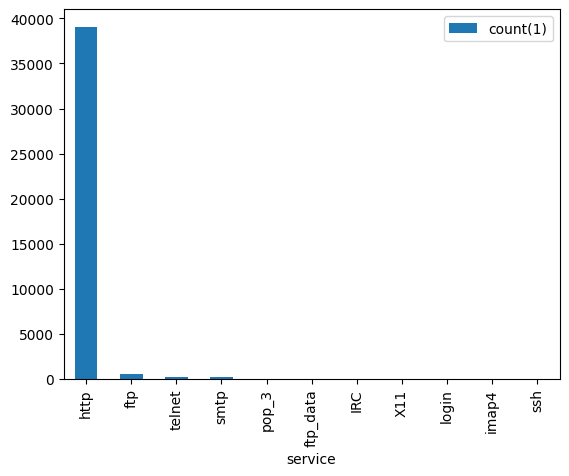

In [32]:
# Plot the services as a bar chart.
Pandas_df=sqlDF.toPandas()
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='service', y='count(1)', kind='bar')
plt.show()

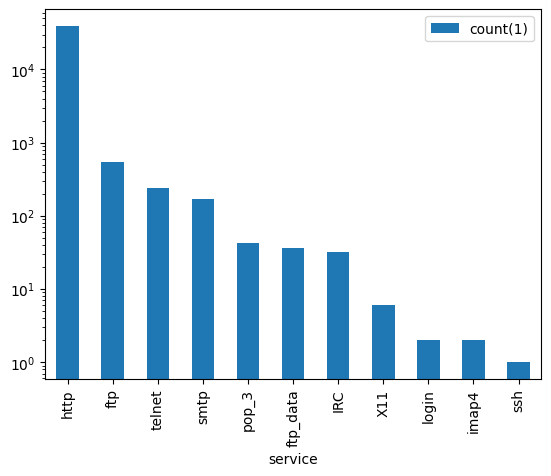

In [34]:
# Plot the services with a logarithmic Y axis.
Pandas_df.sort_values(by='count(1)', ascending=False).plot(x='service', y='count(1)', kind='bar', logy=True)
plt.show()

In [36]:
# Read the file with the full Data Source API and the inferSchema option, then show the types of the first columns.
df_inferred = spark.read.format("csv") \
 .option("inferSchema", True) \
 .load("./kddcup.data_10_percent.gz")
df_inferred.select(df_inferred.columns[:6] + ["_c24", "_c41"]).printSchema()

root
 |-- _c0: integer (nullable = true)
 |-- _c1: string (nullable = true)
 |-- _c2: string (nullable = true)
 |-- _c3: string (nullable = true)
 |-- _c4: integer (nullable = true)
 |-- _c5: integer (nullable = true)
 |-- _c24: double (nullable = true)
 |-- _c41: string (nullable = true)



In [38]:
# Build an explicit schema with the feature names and types, read the file with it, and show the result.
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, LongType

text_columns = ["protocol_type", "service", "flag", "connection_status"]

kdd_schema = StructType([
    StructField(
        name,
        StringType() if name in text_columns else (DoubleType() if "rate" in name else LongType()),
        True
    ) for name in df2.columns
])

kdd_typed = spark.read.schema(kdd_schema).csv("./kddcup.data_10_percent.gz")
kdd_typed.printSchema()
print("rows:", kdd_typed.count())

root
 |-- duration: long (nullable = true)
 |-- protocol_type: string (nullable = true)
 |-- service: string (nullable = true)
 |-- flag: string (nullable = true)
 |-- src_bytes: long (nullable = true)
 |-- dst_bytes: long (nullable = true)
 |-- land: long (nullable = true)
 |-- wrong_fragment: long (nullable = true)
 |-- urgent: long (nullable = true)
 |-- hot: long (nullable = true)
 |-- num_failed_logins: long (nullable = true)
 |-- logged_in: long (nullable = true)
 |-- num_compromised: long (nullable = true)
 |-- root_shell: long (nullable = true)
 |-- su_attempted: long (nullable = true)
 |-- num_root: long (nullable = true)
 |-- num_file_creations: long (nullable = true)
 |-- num_shells: long (nullable = true)
 |-- num_access_files: long (nullable = true)
 |-- num_outbound_cmds: long (nullable = true)
 |-- is_host_login: long (nullable = true)
 |-- is_guest_login: long (nullable = true)
 |-- count: long (nullable = true)
 |-- srv_count: long (nullable = true)
 |-- serror_rate: d

In [39]:
# Write the typed data as CSV with a header, as JSON and as Parquet.
kdd_typed.write.mode("overwrite").option("header",True) .csv("/content/kdd_csv")
kdd_typed.write.mode("overwrite").json("/content/kdd_json")
kdd_typed.write.mode("overwrite").parquet("/content/kdd_parquet")
print("written")

written


In [40]:
# List the files of the Parquet folder, then compare the size of the four copies.
!ls /content/kdd_parquet
!du -sh kddcup.data_10_percent.gz/content/kdd_csv /content/kdd_json /content/kdd_parquet

part-00000-9004ec99-09f7-4435-b258-a19ebdcc8fbb-c000.snappy.parquet  _SUCCESS
du: cannot access 'kddcup.data_10_percent.gz/content/kdd_csv': Not a directory
406M	/content/kdd_json
1.7M	/content/kdd_parquet


In [41]:
# Read the Parquet and JSON copies back, and compare their row counts and first columns.
kdd_parquet=spark.read.parquet("/content/kdd_parquet")
kdd_json=spark.read.json("/content/kdd_json")
print("parquet:", kdd_parquet.count(), "rows.", kdd_parquet.schema.fields[:2])
print("JSON: ", kdd_json.count(), "rows.", kdd_json.schema.fields[:2])

parquet: 494021 rows. [StructField('duration', LongType(), True), StructField('protocol_type', StringType(), True)]
JSON:  494021 rows. [StructField('connection_status', StringType(), True), StructField('count', LongType(), True)]


In [42]:
# Show the plan of a query on the Parquet copy.
kdd_parquet.filter("dst_bytes > 10000").select ("service", "dst_bytes").explain()

== Physical Plan ==
*(1) Filter (isnotnull(dst_bytes#967L) AND (dst_bytes#967L > 10000))
+- *(1) ColumnarToRow
   +- FileScan parquet [service#964,dst_bytes#967L] Batched: true, DataFilters: [isnotnull(dst_bytes#967L), (dst_bytes#967L > 10000)], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/content/kdd_parquet], PartitionFilters: [], PushedFilters: [IsNotNull(dst_bytes), GreaterThan(dst_bytes,10000)], ReadSchema: struct<service:string,dst_bytes:bigint>




In [43]:
# Write the data partitioned by protocol type, then list the folders.
kdd_typed.write.mode("overwrite").partitionBy("protocol_type").parquet("/content/kdd_by_protocol")
!ls /content/kdd_by_protocol

'protocol_type=icmp'  'protocol_type=tcp'  'protocol_type=udp'	 _SUCCESS


In [44]:
# Count the udp connections in the partitioned data, and show the plan.
udp=spark.read.parquet("/content/kdd_by_protocol").filter("protocol_type = 'udp'")
print (" udp connections:", udp.count())
udp.explain()

 udp connections: 20354
== Physical Plan ==
*(1) ColumnarToRow
+- FileScan parquet [duration#1231L,service#1232,flag#1233,src_bytes#1234L,dst_bytes#1235L,land#1236L,wrong_fragment#1237L,urgent#1238L,hot#1239L,num_failed_logins#1240L,logged_in#1241L,num_compromised#1242L,root_shell#1243L,su_attempted#1244L,num_root#1245L,num_file_creations#1246L,num_shells#1247L,num_access_files#1248L,num_outbound_cmds#1249L,is_host_login#1250L,is_guest_login#1251L,count#1252L,srv_count#1253L,serror_rate#1254,srv_serror_rate#1255,... 17 more fields] Batched: true, DataFilters: [], Format: Parquet, Location: InMemoryFileIndex(1 paths)[file:/content/kdd_by_protocol], PartitionFilters: [isnotnull(protocol_type#1272), (protocol_type#1272 = udp)], PushedFilters: [], ReadSchema: struct<duration:bigint,service:string,flag:string,src_bytes:bigint,dst_bytes:bigint,land:bigint,w...




In [45]:
# Create an RDD from a Python list, square each number, and add them up.
sc=spark.sparkContext
numbers=sc.parallelize([1, 2, 3, 4, 5])
squares = numbers.map(lambda x: x * x)
print(squares.collect(), "sum:", squares.reduce(lambda a, b: a + b))

[1, 4, 9, 16, 25] sum: 55


In [47]:
# Read the file as an RDD of text lines, count the lines and partitions, and show the first two.
raw_rdd = sc.textFile("./kddcup.data_10_percent.gz")
print(raw_rdd.count(), "lines.", raw_rdd.getNumPartitions(), "partitions")
raw_rdd.take(2)

494021 lines. 1 partitions


['0,tcp,http,SF,181,5450,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,9,9,1.00,0.00,0.11,0.00,0.00,0.00,0.00,0.00,normal.',
 '0,tcp,http,SF,239,486,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,8,8,0.00,0.00,0.00,0.00,1.00,0.00,0.00,19,19,1.00,0.00,0.05,0.00,0.00,0.00,0.00,0.00,normal.']

In [48]:
# Split each line into a list of fields, and show the first record.
rows=raw_rdd.map(lambda line:line.split(","))
first=rows.first()
print(len(first),"fields:", first)

42 fields: ['0', 'tcp', 'http', 'SF', '181', '5450', '0', '0', '0', '0', '0', '1', '0', '0', '0', '0', '0', '0', '0', '0', '0', '0', '8', '8', '0.00', '0.00', '0.00', '0.00', '1.00', '0.00', '0.00', '9', '9', '1.00', '0.00', '0.11', '0.00', '0.00', '0.00', '0.00', '0.00', 'normal.']


In [49]:
# Count the attack and the normal connections with filter.
attacks= rows.filter (lambda f: f[41] !="normal.")
normal=rows.filter(lambda f: f[41] =="normal.")
print("attacks:", attacks.count(), ".normal:", normal.count())

attacks: 396743 .normal: 97278


In [50]:
# Count the connections for each status with map and reduceByKey, largest first.
status_counts=rows.map(lambda f:(f[41],1)).reduceByKey(lambda a, b:a+b)
status_counts.sortBy(lambda pair:pair[1], ascending=False).take(10)

[('smurf.', 280790),
 ('neptune.', 107201),
 ('normal.', 97278),
 ('back.', 2203),
 ('satan.', 1589),
 ('ipsweep.', 1247),
 ('portsweep.', 1040),
 ('warezclient.', 1020),
 ('teardrop.', 979),
 ('pod.', 264)]

In [52]:
# Total bytes sent for each protocol, connections per protocol, and the number of different services.
print("bytes:", rows.map(lambda f: (f[1], int(f[4]))).reduceByKey(lambda a, b: a + b).collect())
print("connections:", dict(rows.map(lambda f: f[1]).countByValue()))
print("services:", rows.map(lambda f: f[2]).distinct().count())

bytes: [('tcp', 1229530130), ('udp', 1911953), ('icmp', 263272941)]
connections: {'tcp': 190065, 'udp': 20354, 'icmp': 283602}
services: 66


In [53]:
# Show the lineage of status_counts.
print(status_counts.toDebugString().decode())

(1) PythonRDD[233] at RDD at PythonRDD.scala:57 []
 |  MapPartitionsRDD[228] at mapPartitions at PythonRDD.scala:169 []
 |  ShuffledRDD[227] at partitionBy at NativeMethodAccessorImpl.java:0 []
 +-(1) PairwiseRDD[226] at reduceByKey at /tmp/ipykernel_368/3299525964.py:2 []
    |  PythonRDD[225] at reduceByKey at /tmp/ipykernel_368/3299525964.py:2 []
    |  ./kddcup.data_10_percent.gz MapPartitionsRDD[219] at textFile at NativeMethodAccessorImpl.java:0 []
    |  ./kddcup.data_10_percent.gz HadoopRDD[218] at textFile at NativeMethodAccessorImpl.java:0 []


In [54]:
# Keep rows in memory, then time the same count twice.
import time
rows.cache()
for run in (1,2):
  start =time.time()
  n=rows.count()
  print(f"run{run}: {n} rows in {time.time()-start:.2f} S")

run1: 494021 rows in 5.48 S
run2: 494021 rows in 1.29 S


In [55]:
# Get the RDD underneath df2, then turn the status counts RDD into a DataFrame.
print(df2.rdd.first())
counts_df=spark.createDataFrame(status_counts, ["connection_status", "connections"])
counts_df.orderBy("connections", ascending=False). show(5)

Row(duration='0', protocol_type='tcp', service='http', flag='SF', src_bytes='181', dst_bytes='5450', land='0', wrong_fragment='0', urgent='0', hot='0', num_failed_logins='0', logged_in='1', num_compromised='0', root_shell='0', su_attempted='0', num_root='0', num_file_creations='0', num_shells='0', num_access_files='0', num_outbound_cmds='0', is_host_login='0', is_guest_login='0', count='8', srv_count='8', serror_rate='0.00', srv_serror_rate='0.00', rerror_rate='0.00', srv_rerror_rate='0.00', same_srv_rate='1.00', diff_srv_rate='0.00', srv_diff_host_rate='0.00', dst_host_count='9', dst_host_srv_count='9', dst_host_same_srv_rate='1.00', dst_host_diff_srv_rate='0.00', dst_host_same_src_port_rate='0.11', dst_host_srv_diff_host_rate='0.00', dst_host_serror_rate='0.00', dst_host_srv_serror_rate='0.00', dst_host_rerror_rate='0.00', dst_host_srv_rerror_rate='0.00', connection_status='normal.')
+-----------------+-----------+
|connection_status|connections|
+-----------------+-----------+
|    

In [56]:
# Example: the number of attack and normal connections.
spark.sql("""
    SELECT CASE WHEN connection_status = 'normal.' THEN 'normal' ELSE 'attack' END AS type, count(*) AS connections
    FROM KddView
    GROUP BY 1""").show()

+------+-----------+
|  type|connections|
+------+-----------+
|normal|      97278|
|attack|     396743|
+------+-----------+



In [57]:
# Q1: The number of attack and normal connections for each protocol type, and the percentage of attacks.
spark.sql("""
    SELECT protocol_type, CASE WHEN connection_status = 'normal.' THEN 'normal' ELSE 'attack' END AS type, count(*) AS connections
    FROM KddView
    GROUP BY 1, 2""").show()

+-------------+------+-----------+
|protocol_type|  type|connections|
+-------------+------+-----------+
|          tcp|normal|      76813|
|          udp|normal|      19177|
|         icmp|normal|       1288|
|          udp|attack|       1177|
|          tcp|attack|     113252|
|         icmp|attack|     282314|
+-------------+------+-----------+



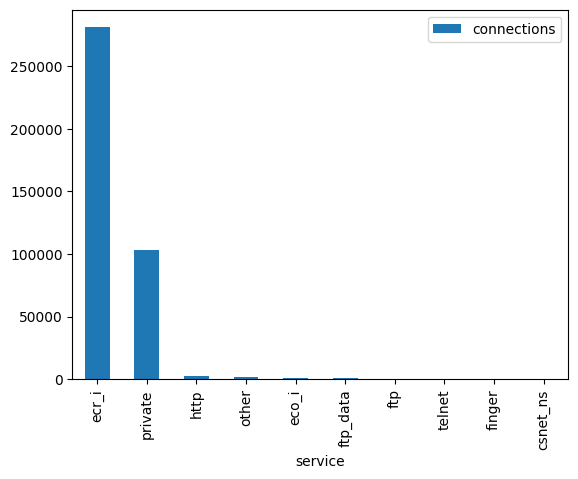

In [63]:
# Q2: The 10 services with the most attack connections, as a bar chart.
sqlDF = spark.sql("""
    SELECT service, count(*) AS connections
    FROM KddView
    WHERE connection_status <> 'normal.'
    GROUP BY service
    ORDER BY connections DESC
    LIMIT 10""")
Pandas_df = sqlDF.toPandas()
Pandas_df.plot(x='service', y='connections', kind='bar')
plt.show()

In [59]:
# Q3: The average src_bytes and dst_bytes of normal connections and of attacks.
spark.sql("""
    SELECT CASE WHEN connection_status = 'normal.' THEN 'normal' ELSE 'attack' END AS type, AVG(src_bytes) AS src_bytes, AVG(dst_bytes) AS dst_bytes
    FROM KddView
    GROUP BY 1
    ORDER BY 1""").show()


+------+------------------+------------------+
|  type|         src_bytes|         dst_bytes|
+------+------------------+------------------+
|attack|3483.7659517622237|251.60160859800928|
|normal| 1157.047523592179| 3384.651000226156|
+------+------------------+------------------+



In [64]:
# Q4: With an RDD and reduceByKey, the number of connections for each flag.
flag_counts = rows.map(lambda f: (f[3], 1)).reduceByKey(lambda a, b: a + b)
flag_counts_sorted = flag_counts.sortBy(lambda pair: pair[1], ascending=False)
for flag, count in flag_counts_sorted.collect():
    print(f"{flag}: {count}")

SF: 378440
S0: 87007
REJ: 26875
RSTR: 903
RSTO: 579
SH: 107
S1: 57
S2: 24
RSTOS0: 11
S3: 10
OTH: 8


In [65]:
# Stop the SparkSession.
spark.stop()